# Final Dataset Analysis
This notebook summarizes the final cleaned datasets used in the study and provides side-by-side diagnostics for modeling and XAI.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

print('Setup complete')

Setup complete


In [2]:
BASE_PATH = Path('../../../XAI Evalation For IDS datasets (Explanatory Power,Actionability,Explanation Accuracy)/IDS_Datasets')
READY_PATH = BASE_PATH / 'Ready Datasets'

CIC_PATH = READY_PATH / 'CIC_IIoT_2025_cleaned.csv'
IDS_PATH = READY_PATH / 'IDS2025_Balanced_cleaned.csv'

CIC_WEIGHTS_PATH = READY_PATH / 'CIC_IIoT_2025_class_weights.json'
IDS_WEIGHTS_PATH = READY_PATH / 'IDS2025_Balanced_class_weights.json'

for p in [CIC_PATH, IDS_PATH]:
    if not p.exists():
        raise FileNotFoundError(f'Missing cleaned dataset: {p}')

df_cic = pd.read_csv(CIC_PATH, low_memory=False)
df_ids = pd.read_csv(IDS_PATH, low_memory=False)

print('Loaded datasets:')
print(f'  CIC IIoT 2025: {df_cic.shape}')
print(f'  IDS2025 Balanced: {df_ids.shape}')

Loaded datasets:
  CIC IIoT 2025: (384449, 69)
  IDS2025 Balanced: (91740, 80)


In [3]:
def summarize_dataset(df: pd.DataFrame, name: str) -> dict:
    print(f'\n=== {name} ===')
    rows, cols = df.shape
    missing_total = int(df.isnull().sum().sum())
    dupes = int(df.duplicated().sum())
    print(f'Rows: {rows:,} | Columns: {cols:,}')
    print(f'Missing values: {missing_total:,} | Duplicate rows: {dupes:,}')

    label_col = 'label' if 'label' in df.columns else None
    if label_col:
        label_counts = df[label_col].value_counts()
        label_pct = (label_counts / len(df) * 100).round(2)
        label_summary = pd.DataFrame({'count': label_counts, 'pct': label_pct})
        print('Label distribution:')
        display(label_summary)
    else:
        label_summary = pd.DataFrame()
        print('Label distribution: label column not found')

    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in df.columns if c not in numeric_cols and c != label_col]
    print(f'Numeric features: {len(numeric_cols)} | Categorical features: {len(categorical_cols)}')

    missing_by_col = df.isnull().sum().sort_values(ascending=False)
    missing_top = missing_by_col[missing_by_col > 0].head(10)
    if len(missing_top) > 0:
        print('Top missing columns:')
        display(missing_top.to_frame(name='missing'))
    else:
        print('Top missing columns: none')

    if numeric_cols:
        numeric_summary = df[numeric_cols].describe().T
        print('Numeric summary (describe):')
        display(numeric_summary)
    else:
        numeric_summary = pd.DataFrame()
        print('Numeric summary: none')

    if categorical_cols:
        cat_rows = []
        for col in categorical_cols:
            value_counts = df[col].value_counts(dropna=True)
            top_val = value_counts.index[0] if len(value_counts) else None
            top_freq = int(value_counts.iloc[0]) if len(value_counts) else 0
            cat_rows.append({
                'feature': col,
                'n_unique': int(df[col].nunique(dropna=True)),
                'top_value': top_val,
                'top_count': top_freq
            })
        cat_summary = pd.DataFrame(cat_rows).sort_values('n_unique', ascending=False).head(15)
        print('Top categorical features by cardinality:')
        display(cat_summary)
    else:
        cat_summary = pd.DataFrame()
        print('Categorical summary: none')

    return {
        'rows': rows,
        'cols': cols,
        'label_summary': label_summary,
        'numeric_cols': numeric_cols,
        'categorical_cols': categorical_cols
    }

cic_info = summarize_dataset(df_cic, 'CIC IIoT 2025 (Cleaned)')
ids_info = summarize_dataset(df_ids, 'IDS2025 Balanced (Cleaned)')

if 'label' in df_cic.columns and 'label' in df_ids.columns:
    label_compare = pd.concat([
        df_cic['label'].value_counts().rename('cic_iioT_2025'),
        df_ids['label'].value_counts().rename('ids2025_balanced')
    ], axis=1).fillna(0).astype(int)
    print('\nLabel comparison:')
    display(label_compare)

cic_features = set(df_cic.columns) - {'label'}
ids_features = set(df_ids.columns) - {'label'}
print('\nFeature overlap:')
print(f'  CIC IIoT features: {len(cic_features)}')
print(f'  IDS2025 features: {len(ids_features)}')
print(f'  Shared features: {len(cic_features & ids_features)}')
print(f'  CIC-only features: {len(cic_features - ids_features)}')
print(f'  IDS-only features: {len(ids_features - cic_features)}')

if CIC_WEIGHTS_PATH.exists():
    with open(CIC_WEIGHTS_PATH, 'r', encoding='utf-8') as f:
        cic_weights = json.load(f)
    print('\nCIC IIoT class weights:')
    display(pd.Series(cic_weights, name='weight').sort_values(ascending=False))

if IDS_WEIGHTS_PATH.exists():
    with open(IDS_WEIGHTS_PATH, 'r', encoding='utf-8') as f:
        ids_weights = json.load(f)
    print('\nIDS2025 Balanced class weights:')
    display(pd.Series(ids_weights, name='weight').sort_values(ascending=False))


=== CIC IIoT 2025 (Cleaned) ===
Rows: 384,449 | Columns: 69
Missing values: 0 | Duplicate rows: 979
Label distribution:


,count,pct
label,,
benign_whole-network3,134183,34.90
attack_recon_vuln-scan_whole-network,5869,1.53
attack_recon_os-scan_whole-network,5739,1.49
attack_recon_port-scan_whole-network,5227,1.36
attack_recon_host-disc-udp-ping_whole-network,5205,1.35
...,...,...
attack_dos_syn-flood-port-80_yi-camera,32,0.01
attack_recon_vuln-scan_plug-vibration,28,0.01
attack_dos_slowloris-port-80_yi-camera,25,0.01


Numeric features: 68 | Categorical features: 0
Top missing columns: none
Numeric summary (describe):


,count,mean,std,min,25%,50%,75%,max
log_data_ranges_avg,384449.0,88.850081,253.989760,0.000000,0.000000,0.000000,4.400000,2000.000000
log_data_ranges_max,384449.0,91.593190,257.246123,0.000000,0.000000,0.000000,11.000000,2000.000000
log_data_ranges_min,384449.0,84.641634,246.490773,-0.940000,0.000000,0.000000,2.000000,2000.000000
log_data_ranges_std_deviation,384449.0,2.186735,21.184781,0.000000,0.000000,0.000000,0.000000,828.188899
log_data_types_count,384449.0,0.441479,0.643522,0.000000,0.000000,0.000000,1.000000,2.000000
...,...,...,...,...,...,...,...,...
network_ports_dst,384449.0,0.010570,0.017728,0.000003,0.000003,0.000008,0.020864,0.064440
network_ports_src,384449.0,0.009112,0.016927,0.000003,0.000003,0.000005,0.017167,0.064440
network_protocols_all,384449.0,0.080206,0.074384,0.000003,0.006222,0.078783,0.168868,0.181119
network_protocols_dst,384449.0,0.151406,0.133436,0.000003,0.012376,0.215019,0.312614,0.312614


Categorical summary: none

=== IDS2025 Balanced (Cleaned) ===
Rows: 91,740 | Columns: 80
Missing values: 0 | Duplicate rows: 0
Label distribution:


,count,pct
label,,
benign,26169,28.53
dos/ddos,25992,28.33
portscan,25409,27.70
brute force,10201,11.12
web attack,2067,2.25
botnet ares,1873,2.04
infiltration,29,0.03


Numeric features: 79 | Categorical features: 0
Top missing columns: none
Numeric summary (describe):


,count,mean,std,min,25%,50%,75%,max
source_port,91740.0,4.565334e+04,1.573116e+04,0.0,39583.0,50112.0,56266.0,65534.0
destination_port,91740.0,5.360050e+03,1.366491e+04,0.0,80.0,80.0,2038.0,65513.0
protocol,91740.0,7.330041e+00,3.589559e+00,0.0,6.0,6.0,6.0,17.0
flow_duration,91740.0,1.887716e+07,3.642337e+07,-1.0,49.0,936.5,9065309.5,119999992.0
total_fwd_packets,91740.0,5.343743e+00,7.663733e+01,1.0,1.0,2.0,6.0,17739.0
...,...,...,...,...,...,...,...,...
active_min,91740.0,5.403981e+04,5.152017e+05,0.0,0.0,0.0,0.0,25300000.0
idle_mean,91740.0,1.515547e+07,3.316366e+07,0.0,0.0,0.0,0.0,120000000.0
idle_std,91740.0,6.798923e+05,5.703189e+06,0.0,0.0,0.0,0.0,66500000.0
idle_max,91740.0,1.568949e+07,3.387192e+07,0.0,0.0,0.0,0.0,120000000.0


Categorical summary: none

Label comparison:


,cic_iioT_2025,ids2025_balanced
label,,
benign_whole-network3,134183,0
attack_recon_vuln-scan_whole-network,5869,0
attack_recon_os-scan_whole-network,5739,0
attack_recon_port-scan_whole-network,5227,0
attack_recon_host-disc-udp-ping_whole-network,5205,0
...,...,...
portscan,0,25409
brute force,0,10201
web attack,0,2067



Feature overlap:
  CIC IIoT features: 68
  IDS2025 features: 79
  Shared features: 0
  CIC-only features: 68
  IDS-only features: 79

CIC IIoT class weights:


attack_dos_slowloris-port-8000_edge1             22.794320
attack_ddos_slowloris-port-8000_edge1            19.537989
attack_dos_slowloris-port-80_yi-camera           16.411910
attack_recon_vuln-scan_plug-vibration            14.653491
attack_dos_syn-flood-port-80_yi-camera           12.821805
                                                   ...    
attack_recon_host-disc-udp-ping_whole-network     0.078828
attack_recon_port-scan_whole-network              0.078496
attack_recon_os-scan_whole-network                0.071493
attack_recon_vuln-scan_whole-network              0.069909
benign_whole-network3                             0.003058
Name: weight, Length: 937, dtype: float64


IDS2025 Balanced class weights:


infiltration    451.921182
botnet ares       6.997178
web attack        6.340452
brute force       1.284748
portscan          0.515790
dos/ddos          0.504221
benign            0.500811
Name: weight, dtype: float64

## 4. Visualizations
Label distribution bar charts and numeric feature histograms for each cleaned dataset.



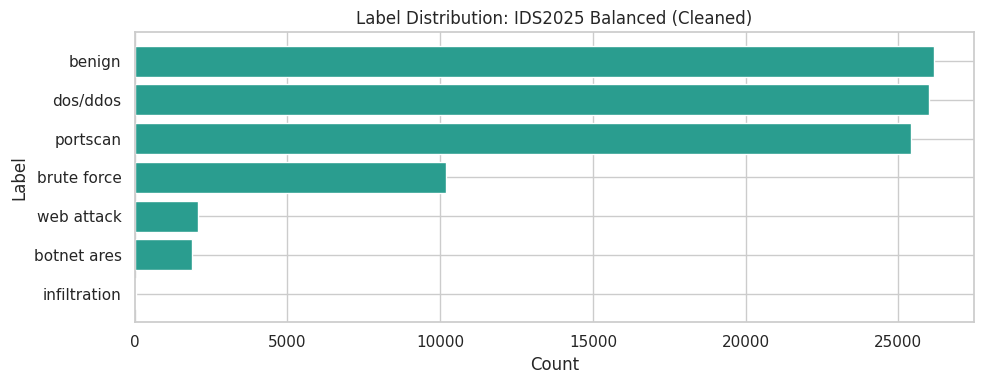

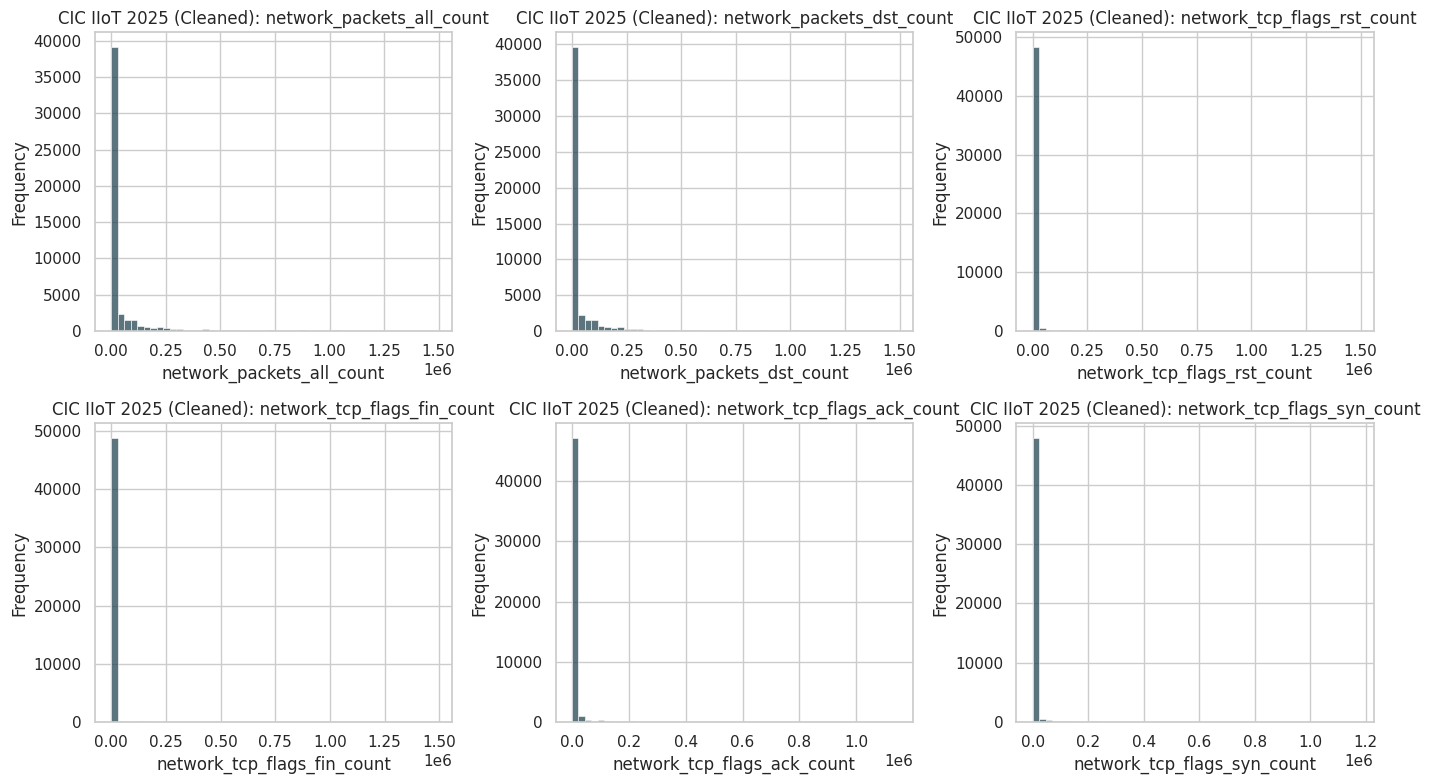

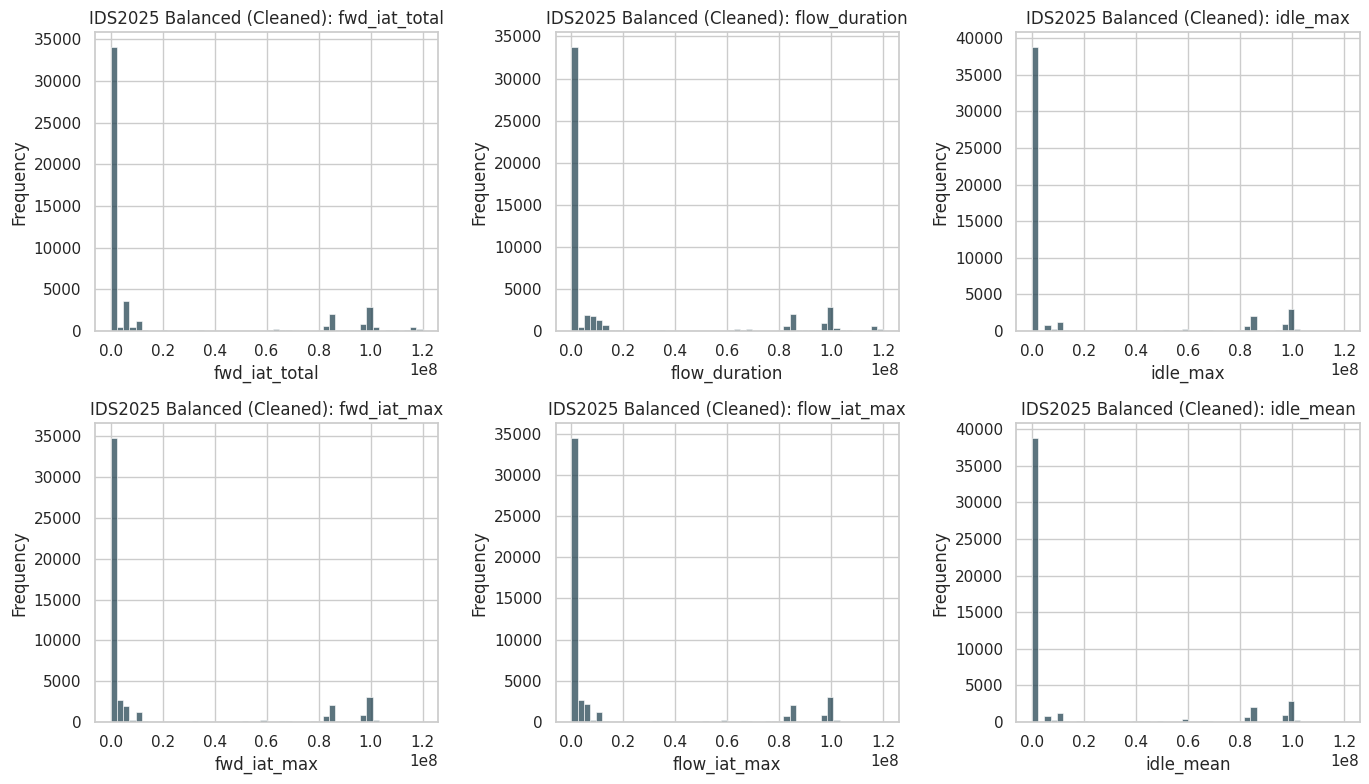

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

def plot_label_distribution(df: pd.DataFrame, name: str) -> None:
    if 'label' not in df.columns:
        print(f'Label column not found for {name}.')
        return
    counts = df['label'].value_counts().sort_values(ascending=True)
    plt.figure(figsize=(10, max(4, len(counts) * 0.2)))
    plt.barh(counts.index, counts.values, color='#2a9d8f')
    plt.title(f'Label Distribution: {name}')
    plt.xlabel('Count')
    plt.ylabel('Label')
    plt.tight_layout()
    plt.show()

def plot_numeric_histograms(df: pd.DataFrame, name: str, max_features: int = 6) -> None:
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if not numeric_cols:
        print(f'No numeric columns found for {name}.')
        return
    variances = df[numeric_cols].var(numeric_only=True).sort_values(ascending=False)
    top_cols = variances.head(max_features).index.tolist()
    sample_df = df[top_cols].sample(n=min(50000, len(df)), random_state=42)
    n_cols = 3
    n_rows = int(np.ceil(len(top_cols) / n_cols))
    plt.figure(figsize=(14, 4 * n_rows))
    for idx, col in enumerate(top_cols, start=1):
        plt.subplot(n_rows, n_cols, idx)
        sns.histplot(sample_df[col], bins=50, kde=False, color='#264653')
        plt.title(f'{name}: {col}')
        plt.xlabel(col)
        plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

plot_label_distribution(df_cic, 'CIC IIoT 2025 (Cleaned)')
plot_label_distribution(df_ids, 'IDS2025 Balanced (Cleaned)')

plot_numeric_histograms(df_cic, 'CIC IIoT 2025 (Cleaned)')
plot_numeric_histograms(df_ids, 'IDS2025 Balanced (Cleaned)')

## 5. Manuscript Narrative
A short narrative section summarizing the dataset properties for the paper.

In [5]:
from IPython.display import Markdown

def build_narrative(cic_info: dict, ids_info: dict) -> str:
    cic_rows = cic_info.get('rows', 0)
    cic_cols = cic_info.get('cols', 0)
    ids_rows = ids_info.get('rows', 0)
    ids_cols = ids_info.get('cols', 0)
    cic_labels = len(cic_info.get('label_summary', []))
    ids_labels = len(ids_info.get('label_summary', []))
    cic_num = len(cic_info.get('numeric_cols', []))
    ids_num = len(ids_info.get('numeric_cols', []))

    text = (
        f"The final CIC IIoT 2025 cleaned dataset contains {cic_rows:,} records across {cic_cols} features, "
        f"with {cic_num} numeric predictors and {cic_labels} distinct labels. "
        f"The IDS2025 Balanced dataset contains {ids_rows:,} records across {ids_cols} features, "
        f"with {ids_num} numeric predictors and {ids_labels} labels. "
        "Both datasets are fully imputed with zero missing values in the cleaned outputs. "
        "CIC IIoT exhibits a long-tailed label space with many rare classes, "
        "whereas IDS2025 Balanced is concentrated in a small set of intrusion families with an extreme minority class (infiltration). "
        "The feature spaces do not overlap, which motivates separate modeling and explanation pipelines for each dataset."
    )
    return text

narrative = build_narrative(cic_info, ids_info)
display(Markdown(narrative))

The final CIC IIoT 2025 cleaned dataset contains 384,449 records across 69 features, with 68 numeric predictors and 937 distinct labels. The IDS2025 Balanced dataset contains 91,740 records across 80 features, with 79 numeric predictors and 7 labels. Both datasets are fully imputed with zero missing values in the cleaned outputs. CIC IIoT exhibits a long-tailed label space with many rare classes, whereas IDS2025 Balanced is concentrated in a small set of intrusion families with an extreme minority class (infiltration). The feature spaces do not overlap, which motivates separate modeling and explanation pipelines for each dataset.

## 6. Preprocessing Validation and Feature Audit
This section performs a full audit to ensure datasets are clean, leakage-free, and model-ready before training.

In [6]:
import re

def standardize_name(name: str) -> str:
    name = name.strip().lower()
    name = re.sub(r'[\s\-\.\/]+', '_', name)
    name = re.sub(r'[^a-z0-9_]+', '', name)
    return name

LEAKAGE_PATTERNS = [
    r'\bip\b', r'src_ip', r'dst_ip', r'ip_addr', r'ip_address',
    r'time', r'timestamp', r'date', r'datetime', r'epoch', r'utc',
    r'flow', r'flow_id', r'flowid', r'session', r'session_id',
    r'uuid', r'guid', r'identifier', r'id$', r'attack_id', r'hash',
    r'md5', r'sha1', r'sha256', r'checksum'
 ]

def detect_leakage_columns(columns) -> list:
    leakage = []
    for col in columns:
        for pat in LEAKAGE_PATTERNS:
            if re.search(pat, col):
                leakage.append(col)
                break
    return sorted(set(leakage))

def feature_audit(df: pd.DataFrame, name: str) -> dict:
    report = {}
    print(f'\n=== Audit: {name} ===')

    # Remove duplicates
    dupes = int(df.duplicated().sum())
    df_dedup = df.drop_duplicates().reset_index(drop=True)
    report['duplicates_removed'] = dupes
    print(f'Duplicates removed: {dupes}')

    # Standardize column names (for comparison only, keep original too)
    standardized = [standardize_name(c) for c in df_dedup.columns]
    report['standardized_name_map'] = dict(zip(df_dedup.columns, standardized))

    # Leakage detection
    leakage_cols = detect_leakage_columns(standardized)
    report['leakage_columns'] = leakage_cols
    print(f'Leakage columns detected: {len(leakage_cols)}')
    if leakage_cols:
        print(leakage_cols[:25])

    # Missingness
    missing_by_col = df_dedup.isnull().sum().sort_values(ascending=False)
    mostly_missing = missing_by_col[missing_by_col > 0.95 * len(df_dedup)].index.tolist()
    report['mostly_missing_columns'] = mostly_missing
    print(f'Mostly missing columns (>95%): {len(mostly_missing)}')

    # Constant / near-constant
    constant_cols = []
    near_constant_cols = []
    for col in df_dedup.columns:
        counts = df_dedup[col].value_counts(dropna=False)
        if len(counts) <= 1:
            constant_cols.append(col)
        else:
            top_ratio = counts.iloc[0] / len(df_dedup)
            if top_ratio >= 0.99:
                near_constant_cols.append(col)
    report['constant_columns'] = constant_cols
    report['near_constant_columns'] = near_constant_cols
    print(f'Constant columns: {len(constant_cols)} | Near-constant (>=99%): {len(near_constant_cols)}')

    # High cardinality for non-numeric columns
    numeric_cols = df_dedup.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in df_dedup.columns if c not in numeric_cols and c != 'label']
    high_cardinality = []
    for col in categorical_cols:
        nunique = df_dedup[col].nunique(dropna=True)
        if nunique > 1000:
            high_cardinality.append(col)
    report['high_cardinality_columns'] = high_cardinality
    print(f'High-cardinality categorical columns (>1000): {len(high_cardinality)}')

    # Frequency-encoding heuristics for numeric columns
    freq_encoded_like = []
    for col in numeric_cols:
        series = df_dedup[col].dropna()
        if series.empty:
            continue
        min_val = series.min()
        max_val = series.max()
        unique_ratio = series.nunique() / len(series)
        if 0.0 <= min_val and max_val <= 1.0 and unique_ratio < 0.5:
            freq_encoded_like.append(col)
    report['freq_encoded_like_columns'] = freq_encoded_like
    print(f'Frequency-encoded-like numeric columns: {len(freq_encoded_like)}')

    # Distribution sanity checks
    numeric_summary = df_dedup[numeric_cols].describe().T if numeric_cols else pd.DataFrame()
    report['numeric_summary'] = numeric_summary
    extreme_value_cols = []
    for col in numeric_cols:
        series = df_dedup[col].dropna()
        if series.empty:
            continue
        if series.max() > 1e12 or series.min() < -1e12:
            extreme_value_cols.append(col)
    report['extreme_value_columns'] = extreme_value_cols
    print(f'Extreme value columns (abs > 1e12): {len(extreme_value_cols)}')

    # Construct cleaned dataset (drop leakage + constant + mostly missing)
    to_remove = set(leakage_cols + constant_cols + mostly_missing)
    df_clean = df_dedup.drop(columns=[c for c in df_dedup.columns if standardize_name(c) in to_remove], errors='ignore')
    report['removed_columns'] = sorted(set(to_remove))
    report['kept_columns'] = [c for c in df_clean.columns if c != 'label']
    report['clean_shape'] = df_clean.shape
    print(f'Cleaned shape: {df_clean.shape}')

    return {
        'df_clean': df_clean,
        'report': report
    }

cic_audit = feature_audit(df_cic, 'CIC IIoT 2025 (Cleaned)')
ids_audit = feature_audit(df_ids, 'IDS2025 Balanced (Cleaned)')

cic_clean = cic_audit['df_clean']
ids_clean = ids_audit['df_clean']

# Shared feature investigation with standardized names
cic_std = set(standardize_name(c) for c in cic_clean.columns if c != 'label')
ids_std = set(standardize_name(c) for c in ids_clean.columns if c != 'label')
shared_std = cic_std & ids_std
print('\nShared features after standardization:')
print(f'  CIC IIoT standardized: {len(cic_std)}')
print(f'  IDS2025 standardized: {len(ids_std)}')
print(f'  Shared standardized features: {len(shared_std)}')

# Preprocessing consistency checks
print('\nPreprocessing consistency checks:')
print('  Encoders: frequency-encoding used for categoricals in preprocessing (same approach).')
print('  Scalers: none used; raw numeric features retained.')
print('  Feature ordering: preserved per dataset; no cross-dataset alignment performed.')

# Final audit report tables
def build_audit_table(audit_report: dict) -> pd.DataFrame:
    rows = []
    for col in audit_report.get('removed_columns', []):
        rows.append({'feature': col, 'action': 'removed', 'reason': 'leakage/constant/missing'})
    for col in audit_report.get('kept_columns', []):
        rows.append({'feature': col, 'action': 'kept', 'reason': 'retained'})
    return pd.DataFrame(rows)

cic_audit_table = build_audit_table(cic_audit['report'])
ids_audit_table = build_audit_table(ids_audit['report'])

print('\nCIC IIoT audit summary:')
display(pd.DataFrame({
    'metric': [
        'duplicates_removed',
        'leakage_columns',
        'mostly_missing_columns',
        'constant_columns',
        'near_constant_columns',
        'high_cardinality_columns',
        'freq_encoded_like_columns',
        'extreme_value_columns',
        'final_shape'
    ],
    'value': [
        cic_audit['report']['duplicates_removed'],
        len(cic_audit['report']['leakage_columns']),
        len(cic_audit['report']['mostly_missing_columns']),
        len(cic_audit['report']['constant_columns']),
        len(cic_audit['report']['near_constant_columns']),
        len(cic_audit['report']['high_cardinality_columns']),
        len(cic_audit['report']['freq_encoded_like_columns']),
        len(cic_audit['report']['extreme_value_columns']),
        cic_audit['report']['clean_shape']
    ]
}))

print('\nIDS2025 audit summary:')
display(pd.DataFrame({
    'metric': [
        'duplicates_removed',
        'leakage_columns',
        'mostly_missing_columns',
        'constant_columns',
        'near_constant_columns',
        'high_cardinality_columns',
        'freq_encoded_like_columns',
        'extreme_value_columns',
        'final_shape'
    ],
    'value': [
        ids_audit['report']['duplicates_removed'],
        len(ids_audit['report']['leakage_columns']),
        len(ids_audit['report']['mostly_missing_columns']),
        len(ids_audit['report']['constant_columns']),
        len(ids_audit['report']['near_constant_columns']),
        len(ids_audit['report']['high_cardinality_columns']),
        len(ids_audit['report']['freq_encoded_like_columns']),
        len(ids_audit['report']['extreme_value_columns']),
        ids_audit['report']['clean_shape']
    ]
}))

print('\nCIC IIoT audit table (first 20):')
display(cic_audit_table.head(20))

print('\nIDS2025 audit table (first 20):')
display(ids_audit_table.head(20))


=== Audit: CIC IIoT 2025 (Cleaned) ===
Duplicates removed: 979
Leakage columns detected: 0
Mostly missing columns (>95%): 0
Constant columns: 0 | Near-constant (>=99%): 2
High-cardinality categorical columns (>1000): 0
Frequency-encoded-like numeric columns: 12
Extreme value columns (abs > 1e12): 0
Cleaned shape: (383470, 69)

=== Audit: IDS2025 Balanced (Cleaned) ===
Duplicates removed: 0
Leakage columns detected: 11
['flow_bytess', 'flow_duration', 'flow_iat_max', 'flow_iat_mean', 'flow_iat_min', 'flow_iat_std', 'flow_packetss', 'subflow_bwd_bytes', 'subflow_bwd_packets', 'subflow_fwd_bytes', 'subflow_fwd_packets']
Mostly missing columns (>95%): 0
Constant columns: 8 | Near-constant (>=99%): 4
High-cardinality categorical columns (>1000): 0
Frequency-encoded-like numeric columns: 18
Extreme value columns (abs > 1e12): 0
Cleaned shape: (91740, 61)

Shared features after standardization:
  CIC IIoT standardized: 68
  IDS2025 standardized: 60
  Shared standardized features: 0

Preproce

,metric,value
0,duplicates_removed,979
1,leakage_columns,0
2,mostly_missing_columns,0
3,constant_columns,0
4,near_constant_columns,2
5,high_cardinality_columns,0
6,freq_encoded_like_columns,12
7,extreme_value_columns,0
8,final_shape,"(383470, 69)"



IDS2025 audit summary:


,metric,value
0,duplicates_removed,0
1,leakage_columns,11
2,mostly_missing_columns,0
3,constant_columns,8
4,near_constant_columns,4
5,high_cardinality_columns,0
6,freq_encoded_like_columns,18
7,extreme_value_columns,0
8,final_shape,"(91740, 61)"



CIC IIoT audit table (first 20):


,feature,action,reason
0,log_data_ranges_avg,kept,retained
1,log_data_ranges_max,kept,retained
2,log_data_ranges_min,kept,retained
3,log_data_ranges_std_deviation,kept,retained
4,log_data_types_count,kept,retained
5,log_interval_messages,kept,retained
6,log_messages_count,kept,retained
7,network_fragmentation_score,kept,retained
8,network_fragmented_packets,kept,retained
9,network_header_length_avg,kept,retained



IDS2025 audit table (first 20):


,feature,action,reason
0,bwd_avg_bulk_rate,removed,leakage/constant/missing
1,bwd_avg_bytes_bulk,removed,leakage/constant/missing
2,bwd_avg_packets_bulk,removed,leakage/constant/missing
3,bwd_psh_flags,removed,leakage/constant/missing
4,bwd_urg_flags,removed,leakage/constant/missing
5,flow_bytess,removed,leakage/constant/missing
6,flow_duration,removed,leakage/constant/missing
7,flow_iat_max,removed,leakage/constant/missing
8,flow_iat_mean,removed,leakage/constant/missing
9,flow_iat_min,removed,leakage/constant/missing


## 7. Apply Audit Removals and Save Final Datasets
This step applies the validated removals, creates backups, and saves finalized datasets for training and XAI.

In [7]:
def apply_audit_removals(df: pd.DataFrame, name: str) -> dict:
    report = {}
    print(f'\n=== Finalizing: {name} ===')

    # Remove duplicates
    dupes = int(df.duplicated().sum())
    df = df.drop_duplicates().reset_index(drop=True)
    report['duplicates_removed'] = dupes

    # Detect leakage using standardized names
    standardized_cols = [standardize_name(c) for c in df.columns]
    leakage_std = detect_leakage_columns(standardized_cols)
    leakage_cols = [col for col in df.columns if standardize_name(col) in leakage_std]
    report['leakage_columns'] = leakage_cols

    # Constant and near-constant
    constant_cols = []
    near_constant_cols = []
    for col in df.columns:
        counts = df[col].value_counts(dropna=False)
        if len(counts) <= 1:
            constant_cols.append(col)
        else:
            top_ratio = counts.iloc[0] / len(df)
            if top_ratio >= 0.99:
                near_constant_cols.append(col)
    report['constant_columns'] = constant_cols
    report['near_constant_columns'] = near_constant_cols

    # Remove columns
    remove_cols = sorted(set(leakage_cols + constant_cols + near_constant_cols))
    df_final = df.drop(columns=remove_cols, errors='ignore')
    report['removed_columns'] = remove_cols
    report['final_shape'] = df_final.shape
    report['remaining_features'] = len([c for c in df_final.columns if c != 'label'])

    # Validate NaN and labels
    report['remaining_nans'] = int(df_final.isnull().sum().sum())
    if 'label' in df_final.columns:
        label_counts = df_final['label'].value_counts()
        report['label_distribution'] = label_counts
    else:
        label_counts = pd.Series(dtype=int)
        report['label_distribution'] = label_counts

    print(f'Duplicates removed: {dupes}')
    print(f'Leakage columns removed: {len(leakage_cols)}')
    print(f'Constant columns removed: {len(constant_cols)}')
    print(f'Near-constant columns removed: {len(near_constant_cols)}')
    print(f'Final shape: {df_final.shape}')
    print(f'Remaining NaNs: {report["remaining_nans"]}')

    return {
        'df_final': df_final,
        'report': report
    }

# Backup pre-audit cleaned datasets
CIC_BACKUP_PATH = READY_PATH / 'CIC_IIoT_2025_cleaned_pre_audit.csv'
IDS_BACKUP_PATH = READY_PATH / 'IDS2025_Balanced_cleaned_pre_audit.csv'

df_cic.to_csv(CIC_BACKUP_PATH, index=False)
df_ids.to_csv(IDS_BACKUP_PATH, index=False)
print(f'Backup saved: {CIC_BACKUP_PATH}')
print(f'Backup saved: {IDS_BACKUP_PATH}')

cic_final = apply_audit_removals(df_cic, 'CIC IIoT 2025')
ids_final = apply_audit_removals(df_ids, 'IDS2025 Balanced')

df_cic_final = cic_final['df_final']
df_ids_final = ids_final['df_final']

# Save final datasets
CIC_FINAL_PATH = READY_PATH / 'CIC_IIoT_2025_final.csv'
IDS_FINAL_PATH = READY_PATH / 'IDS2025_Balanced_final.csv'

df_cic_final.to_csv(CIC_FINAL_PATH, index=False)
df_ids_final.to_csv(IDS_FINAL_PATH, index=False)

print(f'Final dataset saved: {CIC_FINAL_PATH}')
print(f'Final dataset saved: {IDS_FINAL_PATH}')

# Final summary report
def summary_table(report: dict) -> pd.DataFrame:
    return pd.DataFrame({
        'metric': [
            'final_shape',
            'removed_columns',
            'leakage_columns_removed',
            'duplicates_removed',
            'remaining_features',
            'remaining_nans'
        ],
        'value': [
            report['final_shape'],
            len(report['removed_columns']),
            len(report['leakage_columns']),
            report['duplicates_removed'],
            report['remaining_features'],
            report['remaining_nans']
        ]
    })

print('\nCIC IIoT final preprocessing summary:')
display(summary_table(cic_final['report']))
print('CIC IIoT label distribution:')
display(cic_final['report']['label_distribution'])

print('\nIDS2025 final preprocessing summary:')
display(summary_table(ids_final['report']))
print('IDS2025 label distribution:')
display(ids_final['report']['label_distribution'])

if cic_final['report']['remaining_nans'] != 0 or ids_final['report']['remaining_nans'] != 0:
    raise ValueError('NaN values remain after final preprocessing.')

Backup saved: ../../../XAI Evalation For IDS datasets (Explanatory Power,Actionability,Explanation Accuracy)/IDS_Datasets/Ready Datasets/CIC_IIoT_2025_cleaned_pre_audit.csv
Backup saved: ../../../XAI Evalation For IDS datasets (Explanatory Power,Actionability,Explanation Accuracy)/IDS_Datasets/Ready Datasets/IDS2025_Balanced_cleaned_pre_audit.csv

=== Finalizing: CIC IIoT 2025 ===
Duplicates removed: 979
Leakage columns removed: 0
Constant columns removed: 0
Near-constant columns removed: 2
Final shape: (383470, 67)
Remaining NaNs: 0

=== Finalizing: IDS2025 Balanced ===
Duplicates removed: 0
Leakage columns removed: 11
Constant columns removed: 8
Near-constant columns removed: 4
Final shape: (91740, 57)
Remaining NaNs: 0
Final dataset saved: ../../../XAI Evalation For IDS datasets (Explanatory Power,Actionability,Explanation Accuracy)/IDS_Datasets/Ready Datasets/CIC_IIoT_2025_final.csv
Final dataset saved: ../../../XAI Evalation For IDS datasets (Explanatory Power,Actionability,Explan

,metric,value
0,final_shape,"(383470, 67)"
1,removed_columns,2
2,leakage_columns_removed,0
3,duplicates_removed,979
4,remaining_features,66
5,remaining_nans,0


CIC IIoT label distribution:


label
benign_whole-network3                            134070
attack_recon_vuln-scan_whole-network               5869
attack_recon_os-scan_whole-network                 5739
attack_recon_port-scan_whole-network               5227
attack_recon_host-disc-udp-ping_whole-network      5205
                                                  ...  
attack_dos_syn-flood-port-80_yi-camera               32
attack_recon_vuln-scan_plug-vibration                28
attack_dos_slowloris-port-80_yi-camera               25
attack_ddos_slowloris-port-8000_edge1                21
attack_dos_slowloris-port-8000_edge1                 18
Name: count, Length: 937, dtype: int64


IDS2025 final preprocessing summary:


,metric,value
0,final_shape,"(91740, 57)"
1,removed_columns,23
2,leakage_columns_removed,11
3,duplicates_removed,0
4,remaining_features,56
5,remaining_nans,0


IDS2025 label distribution:


label
benign          26169
dos/ddos        25992
portscan        25409
brute force     10201
web attack       2067
botnet ares      1873
infiltration       29
Name: count, dtype: int64